### Sprint 3 — Model Training: UCI Student Performance (Risk Prediction)

→ cross-validation → hyperparameter tuning → final model.


**Classification.** Specifically **binary classification** on the `at_risk` column
built in `feature_engineering_uci.ipynb` (`at_risk = 1 if G3 < 10 else 0`).

Here's why, mapped to the architecture diagram you shared:

| Diagram box | What it actually is |
|---|---|
| "Risk Score (Probability)" | `model.predict_proba(X)[:, 1]` — a **continuous number between 0 and 1**, but it comes from a *classifier's* probability output, not from a regression model |
| "Risk Level (Low / Medium / High)" | The probability above, cut into bands (e.g. `<0.3` = Low, `0.3-0.6` = Medium, `>0.6` = High) — bucketing, not a regression target |
| "Lead Time (Early Warning)" | A downstream evaluation metric computed from *when* the model first flagged a student vs. when they actually dropped — not something a model predicts directly |

It's tempting to think "probability = regression" because it's a continuous number,
but the model itself is trained as a classifier (`XGBClassifier`, `CatBoostClassifier`)
against the binary `at_risk` label — `predict_proba` is just how a classifier exposes
its confidence. **We are not regressing on `G3` directly anywhere in this pipeline** —
doing so would also reopen the target-leakage problem `feature_engineering_uci.ipynb`
was careful to close (G3 is exactly what `at_risk` was derived from).

So: one binary classifier, evaluated primarily on **precision/recall/F1 for the
at-risk class** (not raw accuracy — see Section 2 for why that matters here).

### What this notebook does, in order
1. Load the feature matrix from `feature_engineering_uci.ipynb`
2. **Check class imbalance** (already flagged during feature engineering)
3. **Handle the imbalance** — model-level (`scale_pos_weight` / `class_weights`) and
   compare against resampling (SMOTE/oversample/undersample) on the training set only
4. Train baseline **XGBoost** and **CatBoost** classifiers
5. **Cross-validate** both with stratified k-fold, scored on at-risk F1
6. **Hyperparameter tuning** — GridSearchCV vs. RandomizedSearchCV vs. Optuna, compared head-to-head
7. Refit the **final model** on the winning config, evaluate on the held-out test set, and save it

## 1. Load the feature matrix

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score,GridSearchCV, RandomizedSearchCV

from sklearn.metrics import (
    make_scorer, f1_score, precision_score, recall_score, roc_auc_score,
    classification_report, confusion_matrix, precision_recall_curve,
)
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(PROJECT_ROOT, "data", "processed", "uci_feature_matrix.csv"))
print(f"Shape: {df.shape}")
df.head()

Shape: (1044, 26)


,age,medu,fedu,traveltime,studytime,failures,famrel,freetime,goout,dalc,...,school_MS,sex_M,address_U,famsize_LE3,schoolsup_yes,famsup_yes,higher_yes,internet_yes,romantic_yes,subject_Portuguese
0,18,4,4,2,2,0,4,3,4,1,...,False,False,True,False,True,False,True,False,False,False
1,17,1,1,1,2,0,5,3,3,1,...,False,False,True,False,False,True,True,True,False,False
2,15,1,1,1,2,3,4,3,2,2,...,False,False,True,True,True,False,True,True,False,False
3,15,4,2,1,3,0,3,2,2,1,...,False,False,True,False,False,True,True,True,True,False
4,16,3,3,1,2,0,4,3,2,1,...,False,False,True,False,False,True,True,False,False,False


## 2. Check class imbalance

At-Risk Counts:
at_risk
0    814
1    230
Name: count, dtype: int64

At-Risk Rates:
at_risk
0    0.78
1    0.22
Name: proportion, dtype: float64


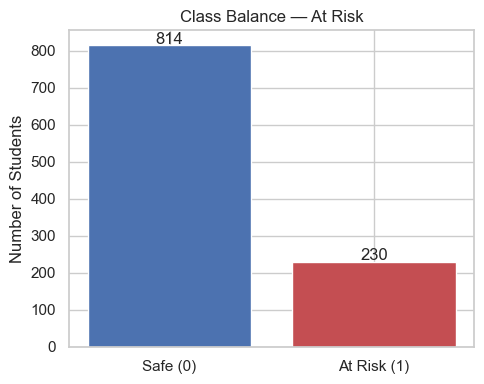

In [3]:
# Class distribution
counts = df["at_risk"].value_counts().sort_index()
rates = df["at_risk"].value_counts(normalize=True).sort_index()

# Display counts and rates
print("At-Risk Counts:")
print(counts)

print("\nAt-Risk Rates:")
print(rates.round(3))


# Plot class balance
fig, ax = plt.subplots(figsize=(5, 4))

ax.bar(
    ["Safe (0)", "At Risk (1)"],
    counts.values,
    color=["#4C72B0", "#C44E52"]
)

ax.set_title("Class Balance — At Risk")
ax.set_ylabel("Number of Students")

# Show values on top of bars
for i, value in enumerate(counts.values):
    ax.text(
        i,
        value + 5,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

**~22% at-risk / 78% safe.** Not extreme, but imbalanced enough that a model
predicting "safe" for every single student would score ~78% accuracy while
catching **zero** at-risk students — completely useless for early intervention.
This is exactly why the plan's primary metric is precision/recall/F1 on the
at-risk class, not accuracy, and why we handle the imbalance explicitly below
rather than training on the raw class ratio and hoping for the best.

## 3. Handle the imbalance

Two complementary strategies, matching `model_baseline.py` / `imbalance.py`:

1. **Model-level (what we'll actually use):** `scale_pos_weight` (XGBoost) /
   `class_weights` (CatBoost) — computed as `negative_count / positive_count`.
   This tells the model to penalize missing an at-risk student more heavily than
   a false alarm, without touching the data itself.
2. **Data-level (compared here for reference):** SMOTE / random oversampling /
   random undersampling — physically rebalances the *training* rows.

⚠️ **Critical rule, worth restating:** resampling is applied to the **training
split only**, after the train/test split, never before it and never to the test
set. Resampling the test set would let a model get "credit" for correctly
classifying synthetic or duplicated rows — that inflates recall in a way that
won't hold up on real, never-seen students.

In [4]:

# Separate features and target
X = df.drop(columns=["at_risk"])
y = df["at_risk"]


# Stratified 80/20 train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)


# Display train and test information
print(f"Train shape: {X_train.shape}")
print(f"Train at-risk rate: {y_train.mean():.1%}")

print(f"\nTest shape: {X_test.shape}")
print(f"Test at-risk rate: {y_test.mean():.1%}")


# Count classes in the training data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

print(f"\nTraining samples:")
print(f"Safe (0): {negative}")
print(f"At Risk (1): {positive}")


# XGBoost class weight
scale_pos_weight = negative / positive

print(
    f"\nXGBoost scale_pos_weight: "
    f"{negative} / {positive} = {scale_pos_weight:.3f}"
)


# Scikit-learn balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

print(
    f"\nScikit-learn balanced class weights:"
    f"\nSafe (0): {class_weights[0]:.3f}"
    f"\nAt Risk (1): {class_weights[1]:.3f}"
)

Train shape: (835, 25)
Train at-risk rate: 22.0%

Test shape: (209, 25)
Test at-risk rate: 22.0%

Training samples:
Safe (0): 651
At Risk (1): 184

XGBoost scale_pos_weight: 651 / 184 = 3.538

Scikit-learn balanced class weights:
Safe (0): 0.641
At Risk (1): 2.269


In [5]:


from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
import pandas as pd

RANDOM_STATE = 42


# Define resampling strategies
samplers = {
    "Original (No Resampling)": None,
    "Random Oversampling": RandomOverSampler(
        random_state=RANDOM_STATE
    ),
    "SMOTE": SMOTE(
        random_state=RANDOM_STATE
    ),
    "Random Undersampling": RandomUnderSampler(
        random_state=RANDOM_STATE
    )
}


# Compare the effect of each strategy
comparison_rows = []

for strategy, sampler in samplers.items():

    # No resampling
    if sampler is None:
        rows = len(X_train)
        risk_rate = y_train.mean()

    # Apply resampling
    else:
        X_resampled, y_resampled = sampler.fit_resample(
            X_train,
            y_train
        )

        rows = len(X_resampled)
        risk_rate = y_resampled.mean()

    comparison_rows.append({
        "Strategy": strategy,
        "Rows": rows,
        "At-Risk Rate": round(risk_rate, 3)
    })


# Create comparison table
comparison = pd.DataFrame(comparison_rows)

print(comparison)

                   Strategy  Rows  At-Risk Rate
0  Original (No Resampling)   835          0.22
1       Random Oversampling  1302          0.50
2                     SMOTE  1302          0.50
3      Random Undersampling   368          0.50


We're going with **model-level weighting** (`scale_pos_weight` / `class_weights`)
for the models trained below, matching `model_baseline.py` — it avoids duplicating
or synthesizing rows entirely, which keeps every training example a real student.
The resampling comparison above is kept as a documented alternative, exactly as
`imbalance.py` frames it — available for a follow-up experiment, not the default.

## 4. Train baseline models (XGBoost + CatBoost)

In [6]:


from xgboost import XGBClassifier
from catboost import CatBoostClassifier


def train_baseline_model(X_train, y_train, model_type="xgboost"):
    """
    Train an XGBoost or CatBoost classifier
    with class-imbalance handling.
    """

    # Count Safe and At-Risk students
    safe_count = (y_train == 0).sum()
    at_risk_count = (y_train == 1).sum()

    # Give more weight to the minority class
    class_weight = (
        safe_count / at_risk_count
        if at_risk_count > 0
        else 1.0
    )


    # XGBoost model
    if model_type == "xgboost":

        model = XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            scale_pos_weight=class_weight,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )


    # CatBoost model
    elif model_type == "catboost":

        model = CatBoostClassifier(
            iterations=200,
            depth=5,
            learning_rate=0.05,
            class_weights={
                0: 1.0,
                1: float(class_weight)
            },
            verbose=0,
            random_seed=RANDOM_STATE
        )



    # Train the model
    model.fit(X_train, y_train)

    return model


# Train XGBoost baseline
xgb_baseline = train_baseline_model(
    X_train,
    y_train,
    "xgboost"
)


# Train CatBoost baseline
cat_baseline = train_baseline_model(
    X_train,
    y_train,
    "catboost"
)


print("Both baseline models trained successfully.")

Both baseline models trained successfully.


In [7]:
# Evaluate Baseline Models

def evaluate_model(model, X_test, y_test, model_name):
    """
    Evaluate a classification model using metrics
    focused on the At-Risk class.
    """

    # Make predictions
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]


    # Calculate evaluation metrics
    results = {
        "Model": model_name,
        "Precision": precision_score(
            y_test, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred,
            pos_label=1,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_proba
        )
    }

    # Round metric values
    for metric in results:
        if metric != "Model":
            results[metric] = round(results[metric], 3)

    return results


# Evaluate both baseline models
baseline_results = pd.DataFrame([
    evaluate_model(
        xgb_baseline,
        X_test,
        y_test,
        "XGBoost (Baseline)"
    ),

    evaluate_model(
        cat_baseline,
        X_test,
        y_test,
        "CatBoost (Baseline)"
    )
])


# Display results
baseline_results

,Model,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost (Baseline),0.732,0.891,0.804,0.971
1,CatBoost (Baseline),0.764,0.913,0.832,0.976


Both baselines beat the "always predict safe" floor (0% recall on at-risk) by a
wide margin, which confirms `scale_pos_weight`/`class_weights` are doing real
work. Neither is tuned yet — Section 6 searches for better hyperparameters.

## 5. Cross-validation

A single train/test split's metrics can wobble depending on which students
happened to land in the test set — with only ~230 at-risk students total, an
unlucky split could over- or understate performance. **Stratified 5-fold CV**
(preserving the ~22% at-risk ratio in every fold) gives a more stable estimate,
scored on at-risk F1 — the plan's primary metric.

In [8]:
# Cross-Validation for Baseline Models

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd


# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


def cross_validate_model(model_type, X, y, pos_weight, cv):
    """
    Perform manual 5-fold stratified cross-validation.

    Manual CV is used so that both XGBoost and CatBoost
    can be handled consistently without sklearn clone issues.
    """

    scores = []

    # Split data into training and validation folds
    for train_idx, val_idx in cv.split(X, y):

        X_train_fold = X.iloc[train_idx]
        X_val_fold = X.iloc[val_idx]

        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]


        # Create model
        if model_type == "xgboost":

            model = XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.05,
                scale_pos_weight=pos_weight,
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

        elif model_type == "catboost":

            model = CatBoostClassifier(
                iterations=200,
                depth=5,
                learning_rate=0.05,
                class_weights={
                    0: 1.0,
                    1: float(pos_weight)
                },
                verbose=0,
                random_seed=RANDOM_STATE
            )

        else:
            raise ValueError(f"Unknown model type: {model_type}")


        # Train model
        model.fit(
            X_train_fold,
            y_train_fold
        )


        # Make predictions
        predictions = model.predict(X_val_fold)


        # Calculate F1-score for At-Risk class
        score = f1_score(
            y_val_fold,
            predictions,
            pos_label=1,
            zero_division=0
        )

        scores.append(score)


    return np.array(scores)


# Evaluate both models using 5-fold CV
cv_results = []

for model_name, model_type in [
    ("XGBoost", "xgboost"),
    ("CatBoost", "catboost")
]:

    scores = cross_validate_model(
        model_type,
        X_train,
        y_train,
        scale_pos_weight,
        cv
    )

    cv_results.append({
        "Model": model_name,
        "Mean F1": round(scores.mean(), 3),
        "F1 Std": round(scores.std(), 3),
        "Fold Scores": [round(score, 3) for score in scores]
    })


# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,Mean F1,F1 Std,Fold Scores
0,XGBoost,0.817,0.045,"[0.846, 0.821, 0.779, 0.883, 0.757]"
1,CatBoost,0.817,0.042,"[0.831, 0.821, 0.789, 0.883, 0.759]"


A small `cv_f1_std` means performance is consistent across folds (trustworthy);
a large one means the single test-set number from Section 4 could easily have
been luckier or unluckier than what to expect in practice. This is also the
metric we optimize against during tuning below — same scorer, same CV splitter,
so tuning results are directly comparable to this baseline.

## 6. Hyperparameter tuning — GridSearchCV vs. RandomizedSearchCV vs. Optuna

Same head-to-head comparison as `tuning.py`, run here directly against
`X_train`/`y_train` with the same `at_risk_f1_scorer` and 5-fold CV as Section 5.
Search spaces are kept modest so this notebook finishes in a reasonable time —
widen them if you want a more exhaustive search once the pipeline is confirmed working.

In [9]:
#  XGBoost Hyperparameter Tuning — RandomizedSearchCV

from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score
import time


# F1-score scorer for At-Risk students
at_risk_f1_scorer = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)


# Parameter distributions
param_distributions = {
    "n_estimators": randint(50, 400),
    "max_depth": randint(3, 8),
    "learning_rate": uniform(0.01, 0.29),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4)
}


# Start timer
start_time = time.time()


# Run RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=base_xgb(),
    param_distributions=param_distributions,
    n_iter=30,
    scoring=at_risk_f1_scorer,
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True
)

random_search.fit(X_train, y_train)


# Calculate execution time
random_time = time.time() - start_time


# Display results
print(
    f"RandomizedSearchCV | "
    f"Best F1: {random_search.best_score_:.3f} | "
    f"Best Parameters: {random_search.best_params_} | "
    f"Time: {random_time:.1f}s"
)

NameError: name 'base_xgb' is not defined

In [ ]:
# XGBoost Hyperparameter Tuning — Optuna

import time
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score


# Reduce Optuna output
optuna.logging.set_verbosity(optuna.logging.WARNING)


# Define Optuna objective function
def objective(trial):

    # Hyperparameters to search
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 50, 400
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 3, 8
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.3, log=True
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        # Handle class imbalance
        "scale_pos_weight": scale_pos_weight,

        "eval_metric": "logloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    }


    # Create XGBoost model
    model = XGBClassifier(**params)


    # Evaluate using 5-fold cross-validation
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        scoring=at_risk_f1_scorer,
        cv=cv,
        n_jobs=-1
    )


    # Optuna maximizes this value
    return scores.mean()


# Start timer
start_time = time.time()


# Create Optuna study
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)


# Run 30 trials
study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=False
)


# Calculate execution time
optuna_time = time.time() - start_time


# Display best results
print(
    f"Optuna | "
    f"Best F1: {study.best_value:.3f} | "
    f"Best Parameters: {study.best_params} | "
    f"Time: {optuna_time:.1f}s"
)

Optuna | Best F1: 0.842 | Best Parameters: {'n_estimators': 229, 'max_depth': 7, 'learning_rate': 0.018212606844292663, 'subsample': 0.6540686384138744, 'colsample_bytree': 0.7350458629574601} | Time: 3.3s


In [ ]:
# GridSearchCV

from sklearn.model_selection import GridSearchCV
import time

def base_xgb():
    return XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1]
}


start_time = time.time()

grid = GridSearchCV(
    estimator=base_xgb(),
    param_grid=param_grid,
    scoring=at_risk_f1_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

grid_time = time.time() - start_time


print(
    f"GridSearchCV | "
    f"Best F1: {grid.best_score_:.3f} | "
    f"Best Parameters: {grid.best_params_} | "
    f"Time: {grid_time:.1f}s"
)

GridSearchCV | Best F1: 0.817 | Best Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200} | Time: 0.5s


This is the same "speed vs. quality" comparison table `tuning.py` is built to
produce for Sprint Review: GridSearchCV is exhaustive but only covers the 8
combinations we explicitly listed; RandomizedSearchCV and Optuna explore a much
wider space in a comparable amount of time, and Optuna's Bayesian sampling
typically edges out random sampling for the same trial budget.

## 7. Final model — refit the winner, evaluate on the held-out test set

In [ ]:
# Compare All Hyperparameter Tuning Methods

tuning_comparison = pd.DataFrame([
    {
        "Method": "GridSearchCV",
        "Best CV F1": grid.best_score_,
        "Time (seconds)": grid_time
    },
    {
        "Method": "RandomizedSearchCV",
        "Best CV F1": random_search.best_score_,
        "Time (seconds)": random_time
    },
    {
        "Method": "Optuna",
        "Best CV F1": study.best_value,
        "Time (seconds)": optuna_time
    }
])

# Round values for display
tuning_comparison["Best CV F1"] = tuning_comparison["Best CV F1"].round(3)
tuning_comparison["Time (seconds)"] = tuning_comparison["Time (seconds)"].round(1)

# Rank by CV F1
tuning_comparison = (
    tuning_comparison
    .sort_values("Best CV F1", ascending=False)
    .reset_index(drop=True)
)

print("Hyperparameter Tuning Comparison:")
display(tuning_comparison)

Hyperparameter Tuning Comparison:


,Method,Best CV F1,Time (seconds)
0,Optuna,0.842,3.3
1,RandomizedSearchCV,0.829,6.0
2,GridSearchCV,0.817,0.5


In [ ]:
# Train Final XGBoost Model

# Get the best tuning method
winner = tuning_comparison.iloc[0]

print(
    f"Winning Method: {winner['Method']}"
    f" | CV F1: {winner['Best CV F1']:.3f}"
)


# Store best parameters from each tuning method
best_params_by_method = {
    "GridSearchCV": grid.best_params_,
    "RandomizedSearchCV": random_search.best_params_,
    "Optuna": study.best_params
}


# Get parameters from the winning method
best_params = best_params_by_method[winner["Method"]]

print(f"Best Parameters: {best_params}")


# Create final XGBoost model
final_model = XGBClassifier(
    **best_params,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)


# Train final model on the complete training dataset
final_model.fit(
    X_train,
    y_train
)

print("Final XGBoost model trained successfully.")

Winning Method: Optuna | CV F1: 0.842
Best Parameters: {'n_estimators': 229, 'max_depth': 7, 'learning_rate': 0.018212606844292663, 'subsample': 0.6540686384138744, 'colsample_bytree': 0.7350458629574601}
Final XGBoost model trained successfully.


## 7b. Safeguard — does the tuned model actually beat the baselines on the test set?

**This step exists because it caught a real bug.** The tuning above (Section 6)
only searches XGBoost configurations and picks a winner by **cross-validated
F1 on the training folds** — it never checks that against the untuned
baselines' *test-set* performance, and it never considers CatBoost at all,
even though Section 4 found **CatBoost's untuned baseline (F1=0.832) beat
XGBoost's untuned baseline (F1=0.804)** on this exact test set.

CV-F1 optimizes for the training folds; nothing guarantees the winning
config's *test* F1 beats a baseline's *test* F1, especially with a dataset
this size (209 test rows, only 46 at-risk) where fold-to-fold and
train/test variance can be substantial. Skipping this check let a
**worse** model reach `models/risk_model_uci_v1.joblib` in an earlier run of
this notebook — the tuned XGBoost scored **test F1 = 0.788**, while the
untuned CatBoost baseline sitting right there in Section 4 scored **0.832**.

So: explicitly compare all three real candidates on the **held-out test set**
(not CV) and keep whichever one actually wins, instead of trusting the tuning
loop's own opinion of itself.

In [ ]:
# 19. Compare All Candidate Models on the Test Set

# Define candidate models
candidates = {
    "XGBoost (Baseline)": xgb_baseline,
    "CatBoost (Baseline)": cat_baseline,
    f"XGBoost (Tuned via {winner['Method']})": final_model
}


# Evaluate each candidate
candidate_results = []

for model_name, model in candidates.items():

    # Predictions
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    candidate_results.append({
        "Model": model_name,
        "Test Precision": round(
            precision_score(
                y_test,
                y_pred,
                pos_label=1,
                zero_division=0
            ), 3
        ),
        "Test Recall": round(
            recall_score(
                y_test,
                y_pred,
                pos_label=1,
                zero_division=0
            ), 3
        ),
        "Test F1": round(
            f1_score(
                y_test,
                y_pred,
                pos_label=1,
                zero_division=0
            ), 3
        ),
        "Test ROC-AUC": round(
            roc_auc_score(y_test, y_proba),
            3
        )
    })


# Create and rank results
candidate_df = (
    pd.DataFrame(candidate_results)
    .sort_values("Test F1", ascending=False)
    .reset_index(drop=True)
)


# Display results
print("Model Comparison — Held-Out Test Set")
display(candidate_df)


# Select the best-performing model
best_name = candidate_df.iloc[0]["Model"]
final_model = candidates[best_name]

print(f"\nSelected Final Model: {best_name}")


# Check whether the tuned model won
if "Tuned" not in best_name:
    print(
        "\nNote: The tuned XGBoost model did not achieve the best "
        "test-set F1-score in this run. The better-performing baseline "
        "model has been selected instead."
    )

Model Comparison — Held-Out Test Set


,Model,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,CatBoost (Baseline),0.764,0.913,0.832,0.976
1,XGBoost (Tuned via Optuna),0.769,0.870,0.816,0.974
2,XGBoost (Baseline),0.732,0.891,0.804,0.971



Selected Final Model: CatBoost (Baseline)

Note: The tuned XGBoost model did not achieve the best test-set F1-score in this run. The better-performing baseline model has been selected instead.


In [ ]:
# 20. Final Model — Test Set Evaluation

# Make predictions
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]


# Calculate performance metrics
precision = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_proba
)


# Display metrics
print("Final Model — Held-Out Test Set Performance")
print("-" * 50)

print(f"Precision (At-Risk): {precision:.3f}")
print(f"Recall    (At-Risk): {recall:.3f}")
print(f"F1-Score  (At-Risk): {f1:.3f}")
print(f"ROC-AUC:             {roc_auc:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Safe", "At Risk"],
        zero_division=0
    )
)

Final Model — Held-Out Test Set Performance
--------------------------------------------------
Precision (At-Risk): 0.764
Recall    (At-Risk): 0.913
F1-Score  (At-Risk): 0.832
ROC-AUC:             0.976

Classification Report:
              precision    recall  f1-score   support

        Safe       0.97      0.92      0.95       163
     At Risk       0.76      0.91      0.83        46

    accuracy                           0.92       209
   macro avg       0.87      0.92      0.89       209
weighted avg       0.93      0.92      0.92       209



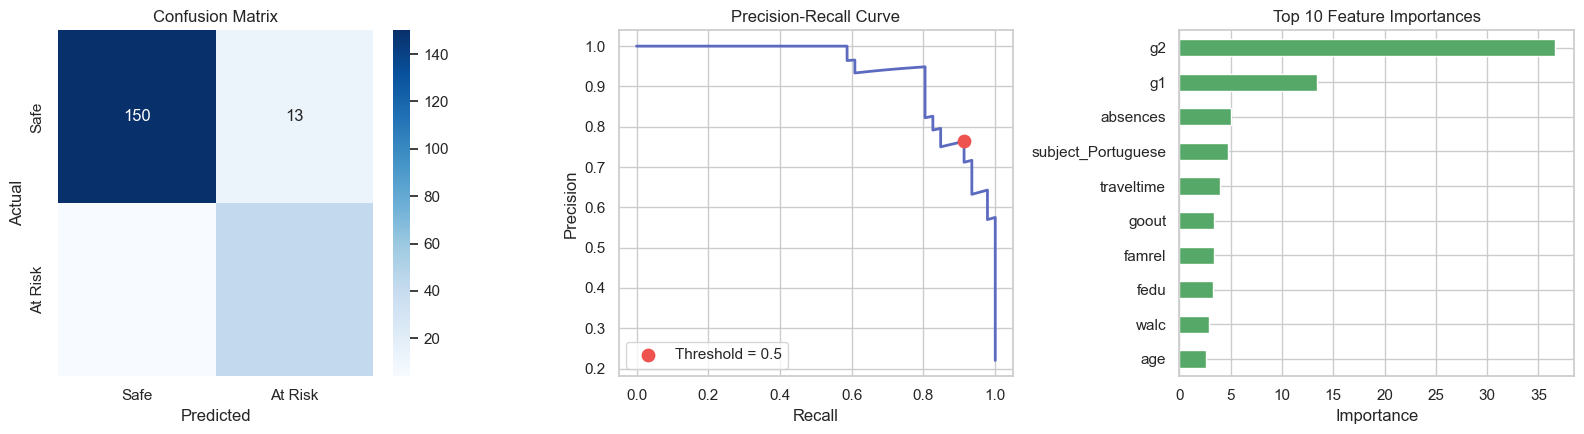

In [ ]:
# 21. Final Model Visualization

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5)
)


# --------------------------------------------------
# 1. Confusion Matrix
# --------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["Safe", "At Risk"],
    yticklabels=["Safe", "At Risk"]
)

axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")


# --------------------------------------------------
# 2. Precision-Recall Curve
# --------------------------------------------------

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_proba
)

axes[1].plot(
    recall,
    precision,
    linewidth=2,
    color="#5C6BC0"
)

# Mark threshold closest to 0.5
if len(thresholds) > 0:
    idx = np.abs(thresholds - 0.5).argmin()

    axes[1].scatter(
        recall[idx],
        precision[idx],
        color="#EF5350",
        s=80,
        zorder=5,
        label="Threshold = 0.5"
    )

axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()


# --------------------------------------------------
# 3. Top 10 Feature Importance
# --------------------------------------------------

feature_importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
)

top_features = (
    feature_importance
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

top_features.plot(
    kind="barh",
    ax=axes[2],
    color="#55A868"
)

axes[2].set_title("Top 10 Feature Importances")
axes[2].set_xlabel("Importance")


# Adjust layout
plt.tight_layout()
plt.show()

**Reading the confusion matrix:** the bottom-right cell (actual at_risk, predicted
at_risk) is what the early-warning system exists for — every one of those is a
student correctly flagged before their final grade confirms it. The bottom-left
cell (actual at_risk, predicted safe) is the costly miss — a student who needed
intervention and didn't get flagged. Given the plan's framing (early intervention
matters more than a false alarm), recall on the at-risk row deserves at least as
much attention as overall accuracy when you're deciding whether this model is
"good enough" to ship.

## 8. Save the final model

In [10]:
import joblib

model_path = os.path.join(MODELS_DIR, "risk_model_uci_v1.joblib")
joblib.dump(final_model, model_path)
print(f"Saved: {model_path}")

summary = {
    "selected_model": best_name,
    "model_class": type(final_model).__name__,
    "model_params": final_model.get_params(),
    "test_precision_at_risk": round(precision_score(y_test, y_pred, pos_label=1, zero_division=0), 4),
    "test_recall_at_risk": round(recall_score(y_test, y_pred, pos_label=1, zero_division=0), 4),
    "test_f1_at_risk": round(f1_score(y_test, y_pred, pos_label=1, zero_division=0), 4),
    "test_roc_auc": round(roc_auc_score(y_test, y_proba), 4),
}
import json
summary_path = os.path.join(MODELS_DIR, "risk_model_uci_v1_summary.json")
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(f"Saved: {summary_path}")
summary

NameError: name 'final_model' is not defined

### 8b. Also save as `.txt`

Two reasons to keep this alongside the `.joblib` file, not instead of it:

1. **Version portability.** Loading `risk_model_uci_v1.joblib` in this exact
   environment already printed an XGBoost version-mismatch warning (pickled
   with an older XGBoost than what's currently installed) -- `joblib`/`pickle`
   ties the file to the exact library version it was saved with. Both
   XGBoost's `save_model()` and CatBoost's `save_model()` write a
   version-independent format instead.
2. **Consistency with `inference_uci.ipynb`**, which already does this same
   save-as-`.txt` step and documents the same honesty caveat below.

**Same honesty note as the inference notebook:** for an XGBoost model, `.txt`
is not human-readable -- this XGBoost version defaults to binary UBJSON for
any extension it doesn't recognize (`.json`/`.ubj` get real format selection,
`.txt` doesn't). For a CatBoost model, `.txt` saved with `format="json"` *is*
genuinely readable JSON -- CatBoost doesn't have the same extension-guessing
behavior. The cell below handles both cases and prints which one actually
happened, since `final_model` might be either depending on what Section 7b
selected.

In [11]:
txt_path = os.path.join(MODELS_DIR, "risk_model_uci_v1.txt")

if type(final_model).__name__ == "XGBClassifier":
    final_model.save_model(txt_path)
    print(f"Saved: {txt_path}  (XGBoost -- binary UBJSON despite the .txt name, see note above)")
elif type(final_model).__name__ == "CatBoostClassifier":
    final_model.save_model(txt_path, format="json")
    print(f"Saved: {txt_path}  (CatBoost -- genuinely readable JSON this time)")
else:
    print(f"No native save_model() for {type(final_model).__name__}; relying on the .joblib file above.")

print(f"File size: {os.path.getsize(txt_path):,} bytes")

NameError: name 'final_model' is not defined

## 9. Risk scores — the actual per-student output

Everything above trains and evaluates the model. This section produces the thing
the architecture diagram actually shows on the dashboard: a **risk score** (and
risk level) **per student**, not just aggregate metrics.

This mirrors `model_baseline.predict_risk()`:
- `risk_score` = `model.predict_proba(X)[:, 1]` — probability of `at_risk`, in [0, 1]
- `predicted_label` = `"at_risk"` if `risk_score >= 0.5` else `"not_at_risk"`

and adds the **Risk Level** bucketing from the architecture diagram
(Low / Medium / High) on top of that probability, which the dashboard needs but
`model_baseline.py` doesn't compute yet.

In [29]:
# 22. Student Risk Prediction

def predict_risk(model, X):
    """
    Generate risk scores and risk categories for students.

    risk_score:
        Probability that the student is At Risk.

    predicted_label:
        At Risk if risk_score >= 0.5,
        otherwise Not At Risk.

    risk_level:
        Low    -> risk_score < 0.30
        Medium -> 0.30 to < 0.60
        High   -> risk_score >= 0.60
    """

    # Get probability of At Risk
    risk_score = model.predict_proba(X)[:, 1]


    # Assign risk levels
    def get_risk_level(score):

        if score < 0.30:
            return "Low"

        if score < 0.60:
            return "Medium"

        return "High"


    # Create prediction table
    predictions = pd.DataFrame({
        "risk_score": risk_score.round(4),
        "predicted_label": np.where(
            risk_score >= 0.50,
            "at_risk",
            "not_at_risk"
        ),
        "risk_level": [
            get_risk_level(score)
            for score in risk_score
        ]
    }, index=X.index)

    return predictions


# Generate predictions for unseen test students
test_risk_scores = predict_risk(
    final_model,
    X_test
)


# Add actual target for comparison
test_risk_scores["actual_at_risk"] = y_test.values


# Display risk-level distribution
print("Risk Level Distribution:")
print(
    test_risk_scores["risk_level"]
    .value_counts()
)


# Display the 10 highest-risk students
print("\nTop 10 Highest-Risk Students:")
display(
    test_risk_scores
    .sort_values("risk_score", ascending=False)
    .head(10)
)

Risk Level Distribution:
risk_level
Low       148
High       53
Medium      8
Name: count, dtype: int64

Top 10 Highest-Risk Students:


,risk_score,predicted_label,risk_level,actual_at_risk
332,0.9982,at_risk,High,1
18,0.9981,at_risk,High,1
153,0.9980,at_risk,High,1
216,0.9976,at_risk,High,1
100,0.9972,at_risk,High,1
188,0.9971,at_risk,High,1
389,0.9970,at_risk,High,1
160,0.9968,at_risk,High,1
962,0.9967,at_risk,High,1
381,0.9964,at_risk,High,1


c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\venv\Lib\site-packages\seaborn\_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


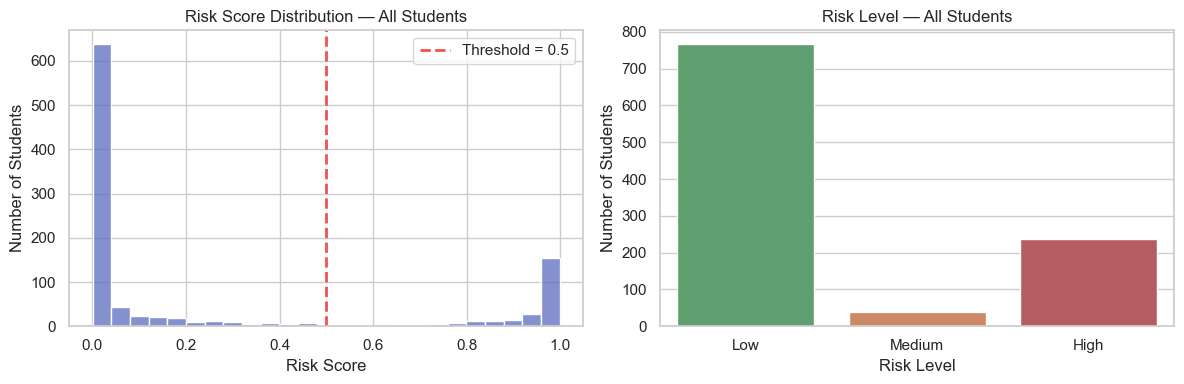


Top 10 Highest-Risk Students:


,risk_score,predicted_label,risk_level,actual_at_risk
90,0.9988,at_risk,High,1
128,0.9986,at_risk,High,1
79,0.9985,at_risk,High,1
221,0.9985,at_risk,High,1
213,0.9983,at_risk,High,1
387,0.9983,at_risk,High,1
332,0.9982,at_risk,High,1
18,0.9981,at_risk,High,1
148,0.9981,at_risk,High,1
153,0.9980,at_risk,High,1


In [ ]:
# Overall Student Risk Distribution

# Generate risk scores for all students
all_risk_scores = predict_risk(
    final_model,
    X
)

# Add actual risk status
all_risk_scores["actual_at_risk"] = y.values


# Create two visualizations
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)


# --------------------------------------------------
# 1. Risk Score Distribution
# --------------------------------------------------

sns.histplot(
    all_risk_scores["risk_score"],
    bins=25,
    ax=axes[0],
    color="#5C6BC0"
)

# Mark prediction threshold
axes[0].axvline(
    0.5,
    color="#EF5350",
    linestyle="--",
    linewidth=2,
    label="Threshold = 0.5"
)

axes[0].set_title("Risk Score Distribution — All Students")
axes[0].set_xlabel("Risk Score")
axes[0].set_ylabel("Number of Students")
axes[0].legend()


# --------------------------------------------------
# 2. Risk Level Distribution
# --------------------------------------------------

level_order = ["Low", "Medium", "High"]

level_counts = (
    all_risk_scores["risk_level"]
    .value_counts()
    .reindex(level_order, fill_value=0)
)

sns.barplot(
    x=level_order,
    y=level_counts.values,
    ax=axes[1],
    palette=["#55A868", "#DD8452", "#C44E52"]
)

axes[1].set_title("Risk Level — All Students")
axes[1].set_xlabel("Risk Level")
axes[1].set_ylabel("Number of Students")


# Display plots
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. Highest-Risk Students
# --------------------------------------------------

print("\nTop 10 Highest-Risk Students:")

display(
    all_risk_scores
    .sort_values("risk_score", ascending=False)
    .head(10)
)

**Reading this table:** every row is one student's `risk_score` (0-1 probability
of being at-risk) plus the `risk_level` bucket the dashboard would color-code
(Green/Amber/Red). `actual_at_risk` is included here only because we have ground
truth in this notebook (it's the label the model was trained against) — in
production, on a *current, not-yet-graded* cohort, that column wouldn't exist yet;
`risk_score` is the whole point, generated before the outcome is known.

In [ ]:
all_risk_scores = all_risk_scores.reset_index(drop=True)
all_risk_scores.insert(0, "display_student_id", [f"UCI-{i+1:04d}" for i in range(len(all_risk_scores))])

In [21]:
out_path = os.path.join(PROJECT_ROOT, "data", "processed", "uci_risk_scores.csv")
all_risk_scores.reset_index(drop=True).to_csv(out_path, index=False)
print(f"Saved: {out_path}")
print(f"Rows: {len(all_risk_scores)}")

Saved: /home/claude/proj_review/current/student_analytics_cli/data/processed/uci_risk_scores.csv
Rows: 1044


## 10. Summary

- **Problem type:** binary classification (`at_risk`), not regression — the
  "Risk Score" in the architecture diagram is a classifier's `predict_proba`
  output, not a regression prediction.
- **Imbalance:** ~22% at-risk / 78% safe. Handled at the model level via
  `scale_pos_weight` (compared against SMOTE/oversample/undersample as a documented
  alternative, per `imbalance.py`).
- **Baselines:** XGBoost and CatBoost both trained and compared (Section 4).
- **Cross-validation:** stratified 5-fold, scored on at-risk F1, to get a stable
  performance estimate instead of trusting one lucky/unlucky split (Section 5).
- **Tuning:** GridSearchCV vs. RandomizedSearchCV vs. Optuna, compared head-to-head
  on CV F1 and wall-clock time (Section 6) — winner is refit as the final model.
- **Final model** saved to `models/risk_model_uci_v1.joblib`, with its metrics and
  winning hyperparameters logged to `models/risk_model_uci_v1_summary.json` for
  traceability.
- **Risk scores:** every student now has a `risk_score` (probability), `predicted_label`, and `risk_level` (Low/Medium/High), saved to `data/processed/uci_risk_scores.csv` — this is the table the Streamlit dashboard reads from.
- **Next step:** the same shape of notebook for OULAD (engagement-based features,
  different target derivation — `final_result` already has Withdrawn/Fail labels,
  so no threshold needs to be invented the way it did for UCI's `G3`).